<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and fixture provenance](README.md)

# 01 · Inventory is not confirmation of device state

Can a light with a brightness value be off? Can a reachable sensor still have no usable reading? We will separate stored settings, power and reachability, then build a battery review list whose threshold is an explicit policy choice.

**All inputs are synthetic.** The repository's existing CLIP v2 mock bridge runs on an ephemeral loopback port. The unchanged, Git-pinned Hue worker reads it through VGI. No real Hue bridge is discovered, no credentials are needed, and this notebook issues no device commands. Percentages describe fixture values; they do not measure electricity, light output or battery lifetime.

## Choose a battery review threshold

`BATTERY_THRESHOLD_PCT` is inclusive: a known battery reading at or below it enters the review list. Accept any integer from **0 to 100**. The focused experiment changes **20 → 80** while keeping every source row unchanged. Predict a list that can grow but cannot shrink.

Restart Kernel → Run All after editing. The synthetic source contains fixed November/October 2026 sensor change timestamps; execution time is not a new observation time.

In [1]:
BATTERY_THRESHOLD_PCT = 20  # Integer percent, 0–100 inclusive; experiment: 80

In [2]:
import hashlib
from tempfile import TemporaryDirectory

import haybarn
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from fixture_bridge import FixtureBridge

assert type(BATTERY_THRESHOLD_PCT) is int and 0 <= BATTERY_THRESHOLD_PCT <= 100
bridge = FixtureBridge()
FIXTURE_BRIDGE_URL = bridge.url
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        "Source: synthetic CLIP v2 fixture · pinned Hue worker 08f4dc8 · fixed fixture state, not live devices",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.07, 1, 0.97))
    plt.show()


secret_directory = TemporaryDirectory(prefix="vgi-notebook-secrets-")
con = haybarn.connect(config={"secret_directory": secret_directory.name, "allow_persistent_secrets": False})
assert con.execute("SELECT count(*) FROM duckdb_secrets()").fetchall() == [(0,)]
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-hue--hue-worker/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-hue--hue-worker/notebooks/pyproject.toml.

## Connect to the published source revision and read inventory once

The literal command fetches commit `08f4dc8e20cf8f0717093cda99dc1035fa91f397`, checks out that exact revision and installs its frozen Bun dependencies in a cache. The companion launcher requires Bun and Git, not this worker checkout. Setup diagnostics go to stderr; stdout carries Arrow.

Explicit `bridge` and `app_key` options take precedence over real-device environment settings. The visible bridge option uses only the owned loopback fixture URL. Materialize both inventories before computing any charts; later SELECTs remain local.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'hue' (
 TYPE vgi,
 LOCATION 'bun run github_worker.ts Query-farm/vgi-hue-typescript 08f4dc8e20cf8f0717093cda99dc1035fa91f397 src/worker.ts',
 bridge '{{FIXTURE_BRIDGE_URL}}',
 app_key 'test-key'
);
CREATE TABLE light_inventory AS
 SELECT light_id,name,room,is_on,brightness,reachable FROM hue.main.lights;
CREATE TABLE sensor_inventory AS SELECT * FROM hue.main.sensors;

,Count


In [4]:
light_source = con.execute("SELECT * FROM light_inventory ORDER BY light_id").df()
sensor_source = con.execute("SELECT * FROM sensor_inventory ORDER BY sensor_id").df()
fingerprint = hashlib.sha256(
    (
        light_source.to_json(orient="records") + sensor_source.to_json(orient="records", date_format="iso")
    ).encode()
).hexdigest()
assert light_source.light_id.is_unique and sensor_source.sensor_id.is_unique
assert light_source.brightness.dropna().between(0, 100).all()
assert sensor_source.battery_percent.dropna().between(0, 100).all()
prose(
    f"Materialized **{len(light_source)} lights** and **{len(sensor_source)} sensor-service rows** from the synthetic bridge. One physical sensor can expose several service rows; the battery analysis will select only `device_power`. Source fingerprint: `{fingerprint}`."
)

Materialized **5 lights** and **15 sensor-service rows** from the synthetic bridge. One physical sensor can expose several service rows; the battery analysis will select only `device_power`. Source fingerprint: `ee04b15bd7dedc58ea967f1acfbab895cbbf6ec34ddfe2d0900f267f12d847ff`.

## Separate settings from evidence about state

Classify reachability first. An unreachable light's reported on/off flag and brightness can be stale. Among reachable lights, keep the reported power flag separate from the brightness setting. A brightness value on an off light is retained configuration, not emitted light.

A reachable/on report is still the bridge's state, not an independent physical measurement. No conversion to lumens, watts, energy or room-wide brightness is justified by these columns.

In [5]:
%%sql
CREATE TABLE light_states AS
SELECT *,CASE
 WHEN reachable IS FALSE THEN 'Unreachable'
 WHEN reachable IS NULL THEN 'Reachability unavailable'
 WHEN is_on IS TRUE THEN 'Reachable / reported on'
 WHEN is_on IS FALSE THEN 'Reachable / reported off'
 ELSE 'Power unavailable' END AS state
FROM light_inventory;

,Count


In [6]:
%%sql lights <<
SELECT name,room,is_on,reachable,brightness,state
FROM light_states ORDER BY room,name;

In [7]:
display(lights)
off_retained = int(((lights.is_on.eq(False)) & lights.brightness.gt(0)).sum())
unreachable = int((lights.reachable.ne(True)).sum())
prose(
    f"**{off_retained} off lights retain a positive brightness setting**; **{unreachable} light is not confirmed reachable**. These rows make an unqualified average of brightness misleading as a description of current illumination. The chart preserves every known setting and labels the separate state."
)

,name,room,is_on,reachable,brightness,state
0,Hallway strip,Hallway,False,True,60.0,Reachable / reported off
1,Kitchen ceiling,Kitchen,True,True,80.0,Reachable / reported on
2,Kitchen pendant,Kitchen,True,True,50.0,Reachable / reported on
3,Desk lamp,Living room,True,False,100.0,Unreachable
4,Sofa lamp,Living room,False,True,30.0,Reachable / reported off


**2 off lights retain a positive brightness setting**; **1 light is not confirmed reachable**. These rows make an unqualified average of brightness misleading as a description of current illumination. The chart preserves every known setting and labels the separate state.

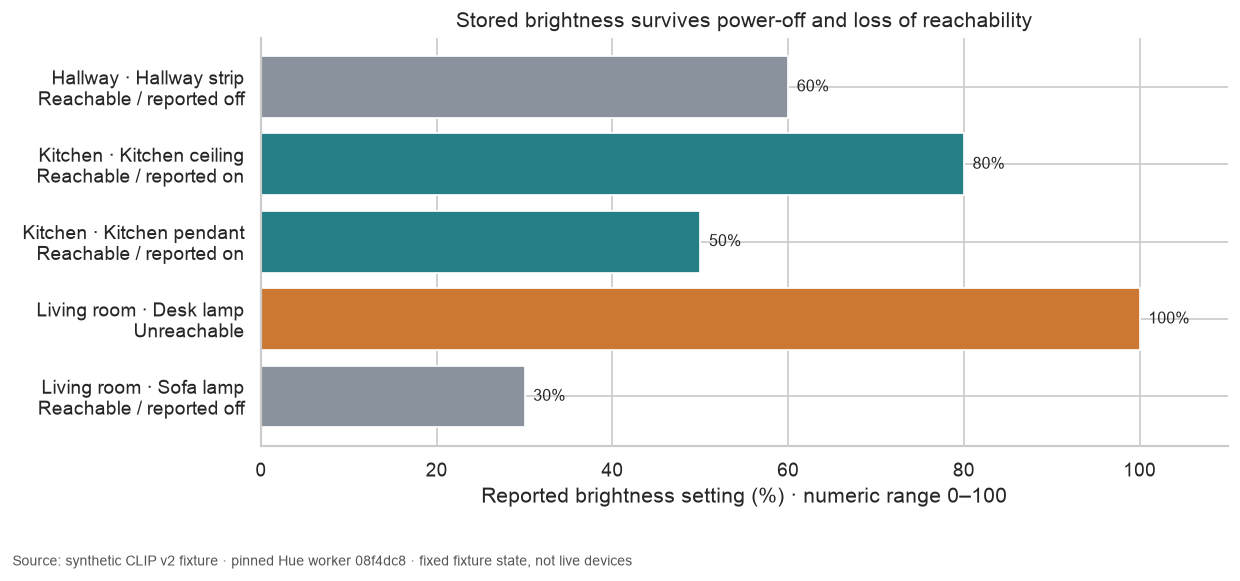

In [8]:
palette = {
    "Reachable / reported on": "#247f86",
    "Reachable / reported off": "#8a939d",
    "Unreachable": "#cc7832",
    "Reachability unavailable": "#cc7832",
    "Power unavailable": "#7464a4",
}
fig, ax = plt.subplots(figsize=(10, 4.8))
known = lights[lights.brightness.notna()]
labels = [f"{r.room} · {r.name}\n{r.state}" for r in known.itertuples()]
bars = ax.barh(labels, known.brightness, color=[palette[s] for s in known.state])
ax.bar_label(bars, labels=[f"{r.brightness:g}%" for r in known.itertuples()], padding=5, fontsize=9)
ax.invert_yaxis()
ax.set(
    xlim=(0, 110),
    xlabel="Reported brightness setting (%) · numeric range 0–100",
    title="Stored brightness survives power-off and loss of reachability",
)
ax.set_xticks([0, 20, 40, 60, 80, 100])
finish(fig)

## Missing readings are not zero readings

The worker keeps disabled sensor services in the inventory but clears their reading and `last_changed` columns, because their bridge payload can contain stale values. Battery services have no enabled flag and remain a separate reading kind. `NULL` enabled on a battery row does not mean disabled.

Group diagnostics by kind. A motion value of false is a known reading, while a disabled sensor's NULL is unavailable. `last_changed` is the timestamp of a value change, not a polling or freshness guarantee; battery rows carry no such timestamp here.

In [9]:
%%sql sensor_quality <<
SELECT kind,count(*) AS service_rows,
 count(*) FILTER (WHERE enabled IS FALSE) AS disabled,
 count(*) FILTER (WHERE CASE kind
   WHEN 'motion' THEN motion IS NOT NULL
   WHEN 'temperature' THEN temperature_c IS NOT NULL
   WHEN 'light_level' THEN light_level_lux IS NOT NULL
   WHEN 'contact' THEN contact IS NOT NULL
   WHEN 'device_power' THEN battery_percent IS NOT NULL END) AS known_readings,
 count(last_changed) AS with_change_timestamp
FROM sensor_inventory GROUP BY kind ORDER BY kind;

In [10]:
display(sensor_quality)
disabled = sensor_source[sensor_source.enabled.eq(False)]
reading_columns = ["motion", "temperature_c", "light_level_lux", "contact", "last_changed"]
assert disabled[reading_columns].isna().all().all()
assert sensor_quality.service_rows.sum() == len(sensor_source)
assert sensor_quality.known_readings.le(sensor_quality.service_rows).all()
prose(
    f"**{len(disabled)} disabled services** remain visible with unavailable readings and timestamps. Across all kinds, **{int(sensor_quality.known_readings.sum())} of {len(sensor_source)} service rows** have a known kind-specific value. Treating NULL as zero would invent measurements and erase the disabled-state distinction."
)

,kind,service_rows,disabled,known_readings,with_change_timestamp
0,contact,1,0,1,1
1,device_power,5,0,5,0
2,light_level,3,1,2,2
3,motion,3,1,2,2
4,temperature,3,1,2,2


**3 disabled services** remain visible with unavailable readings and timestamps. Across all kinds, **12 of 15 service rows** have a known kind-specific value. Treating NULL as zero would invent measurements and erase the disabled-state distinction.

## Apply a transparent battery policy at one row per device

Only `device_power` rows enter this table. A known percentage at or below the chosen threshold is a review candidate. Preserve the bridge's own `battery_state` label, which is a different classification; changing our threshold does not change that label or the device.

Missing values remain unavailable, never zero. Reachability and missing change timestamps stay visible so this list cannot be mistaken for a guarantee of battery condition.

In [11]:
%%sql batteries <<
SELECT device_id,device_name,room,battery_percent,battery_state,reachable,last_changed,
 CASE WHEN battery_percent IS NULL THEN 'Unavailable percentage'
      WHEN battery_percent<={{BATTERY_THRESHOLD_PCT}} THEN 'Review candidate'
      ELSE 'Above threshold' END AS policy
FROM sensor_inventory WHERE kind='device_power'
ORDER BY battery_percent NULLS LAST,device_name;

In [12]:
display(batteries)
assert batteries.device_id.is_unique
known_batteries = batteries[batteries.battery_percent.notna()]
candidates = batteries[batteries.policy == "Review candidate"]
assert len(candidates) == int(known_batteries.battery_percent.le(BATTERY_THRESHOLD_PCT).sum())
assert candidates.battery_percent.notna().all()
missing_time = int(batteries.last_changed.isna().sum())
prose(
    f"At **≤ {BATTERY_THRESHOLD_PCT}%**, **{len(candidates)} of {len(known_batteries)} known battery readings** enter the review list: **{', '.join(candidates.device_name) or 'none'}**. **{len(batteries) - len(known_batteries)} percentages are unavailable**. All **{missing_time} missing change timestamps** remain unavailable; the notebook makes no remaining-life or freshness estimate."
)

,device_id,device_name,room,battery_percent,battery_state,reachable,last_changed,policy
0,d-hsensor,Hallway sensor,Hallway,15,low,True,NaT,Review candidate
1,d-dial,Hue tap dial switch,Living room,74,normal,True,NaT,Above threshold
2,d-ksensor,Kitchen sensor,Kitchen,80,normal,True,NaT,Above threshold
3,d-door,Front door,Hallway,90,normal,True,NaT,Above threshold
4,d-lsensor,Living room sensor,Living room,100,normal,True,NaT,Above threshold


At **≤ 20%**, **1 of 5 known battery readings** enter the review list: **Hallway sensor**. **0 percentages are unavailable**. All **5 missing change timestamps** remain unavailable; the notebook makes no remaining-life or freshness estimate.

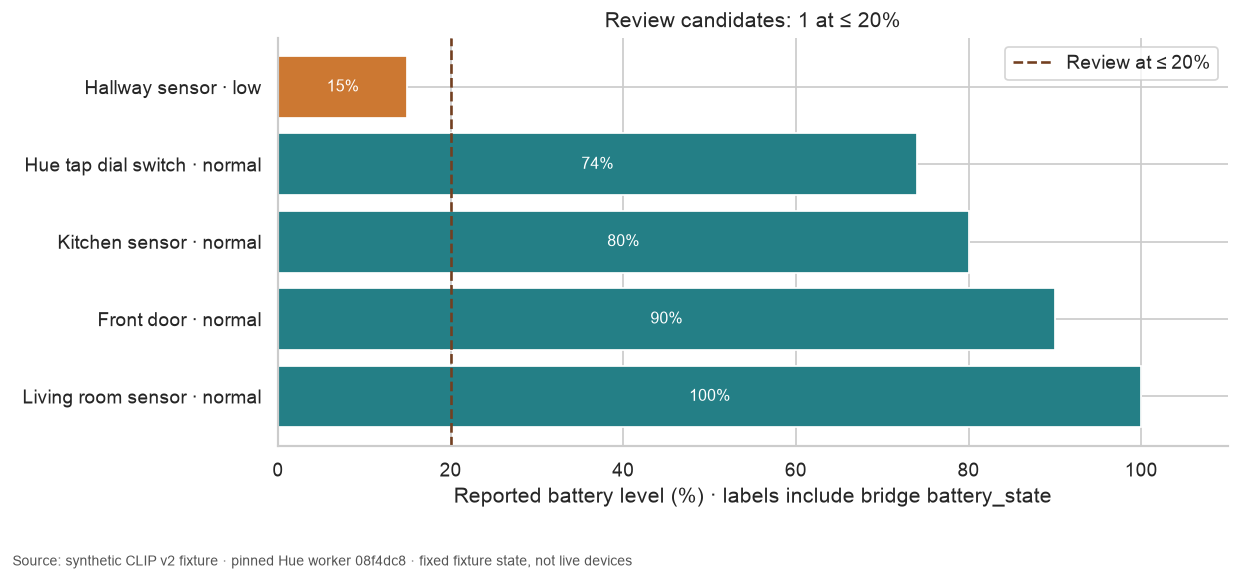

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(
    [f"{r.device_name} · {r.battery_state}" for r in known_batteries.itertuples()],
    known_batteries.battery_percent,
    color=["#cc7832" if x == "Review candidate" else "#247f86" for x in known_batteries.policy],
)
ax.bar_label(
    bars,
    labels=[f"{r.battery_percent:g}%" for r in known_batteries.itertuples()],
    label_type="center",
    color="white",
    fontsize=9,
)
ax.axvline(
    BATTERY_THRESHOLD_PCT, color="#733f20", linestyle="--", label=f"Review at ≤ {BATTERY_THRESHOLD_PCT}%"
)
ax.invert_yaxis()
ax.set(
    xlim=(0, 110),
    xlabel="Reported battery level (%) · labels include bridge battery_state",
    title=f"Review candidates: {len(candidates)} at ≤ {BATTERY_THRESHOLD_PCT}%",
)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.legend(loc="upper right")
finish(fig)

## Experiment: raise only the review threshold

Change `BATTERY_THRESHOLD_PCT` from **20 to 80** in a separate executed copy. Compare the review list and its chart colors. The source fingerprint, inventory rows, brightness chart and bridge battery labels must stay identical. The candidate count can only stay the same or increase because the rule is inclusive. Restore **20** afterwards.

A longer review list reflects a broader policy, not declining batteries. These synthetic values validate the worker's mapping and the SQL population rules; they do not describe a home, establish a maintenance schedule or authorize device changes.

In [14]:
assert bridge.writes() == []
prose("**Read-only check passed:** the owned mock bridge recorded zero device PUT commands.")

**Read-only check passed:** the owned mock bridge recorded zero device PUT commands.

In [15]:
assert con.execute("SELECT count(*) FROM duckdb_secrets()").fetchall() == [(0,)]
con.close()
bridge.close()
secret_directory.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)